# Práctica de Deep Learning para Finanzas · Avance 2 (capítulo 8)
**Ciencia de Datos Aplicada a la Economía** · Prof. Rubén Miguel Rodríguez Rangel · Luis Enrique López Salazar

Tema: redes neuronales, optimización y regularización. Se construyen y comparan un **MLP** y una **LSTM** con el mismo objetivo,
las mismas 20 variables (rendimientos rezagados) y las mismas particiones TR–VA–TE del Avance 1.

Entregable (protocolo §5): tabla de experimentos, curvas, evidencia de T4 y selección justificada. **TE no se usa.**

**Cómo correrlo:** en Colab, *Entorno de ejecución → Cambiar tipo de entorno → GPU T4*, y luego *Ejecutar todas*.
La celda 2 pide subir `avance2_insumos.zip` (datos y referencias del Avance 1).

## 1. Configuración, versiones y semilla

In [1]:
import json, os, platform, shutil, subprocess, sys, time
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib, sklearn, torch, joblib
import matplotlib.pyplot as plt
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEMILLA = 42
SEMILLAS = [42, 43, 44]                  # repetición de la mejor configuración de cada red
PRUEBA_CPU = "EPOCAS_PRUEBA" in os.environ   # solo para probar el flujo fuera de Colab; no es evidencia de T4
EPOCAS_MAX = int(os.environ.get("EPOCAS_PRUEBA", 300))
PACIENCIA = 25                           # parada temprana: épocas sin mejorar la pérdida de VA
LOTE, LR = 64, 1e-3
VENTANA = 20
CONFIG = {"MLP": [16, 32, 64], "LSTM": [8, 16, 32]}   # tres configuraciones por red: solo cambian las neuronas
EN_COLAB = "google.colab" in sys.modules
for d in ["data/processed", "outputs/curvas", "figures", "checkpoints"]:
    os.makedirs(d, exist_ok=True)
VERSIONES = {"python": platform.python_version(), "torch": torch.__version__, "cuda": torch.version.cuda,
             "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__}
print(VERSIONES, "| semilla", SEMILLA, "| épocas máx.", EPOCAS_MAX, "| Colab:", EN_COLAB)

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'cuda': '13.0', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1'} | semilla 42 | épocas máx. 300 | Colab: True


## 2. Insumos del Avance 1

In [2]:
INSUMOS = ["data/processed/ventanas_btcusdt_1d.csv", "outputs/particiones_avance1.csv", "outputs/metricas_referencia_avance1.csv"]
if EN_COLAB and not all(map(os.path.exists, INSUMOS)):
    from google.colab import files
    print("Sube avance2_insumos.zip")
    shutil.unpack_archive(next(iter(files.upload())), ".")
faltan = [f for f in INSUMOS if not os.path.exists(f)]
if faltan:
    raise FileNotFoundError(f"Faltan insumos del Avance 1: {faltan}. Detengo el flujo.")
print("insumos:", INSUMOS)

insumos: ['data/processed/ventanas_btcusdt_1d.csv', 'outputs/particiones_avance1.csv', 'outputs/metricas_referencia_avance1.csv']


## 3. Evidencia de T4 (protocolo §4)
Se guarda la salida de `nvidia-smi`, se verifica que PyTorch reconoce la T4 y se ejecuta una operación en ella.
Si falta la T4, **se detiene el entrenamiento profundo** y se registra el incidente en `outputs/incidente_t4.json`.

In [3]:
smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True) if shutil.which("nvidia-smi") else None
TEXTO_SMI = smi.stdout if smi and smi.returncode == 0 else "nvidia-smi no disponible"
open("outputs/nvidia_smi.txt", "w").write(TEXTO_SMI)
print(TEXTO_SMI)
GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "ninguna"
ES_T4 = "T4" in GPU and "T4" in TEXTO_SMI
if ES_T4:
    DISPOSITIVO = torch.device("cuda")
    a = torch.randn(2048, 2048, device=DISPOSITIVO)
    t0 = time.time(); s = (a @ a).sum().item(); torch.cuda.synchronize()
    print(f"PyTorch ve: {GPU} | operación de prueba en {a.device}: suma={s:.1f} en {time.time() - t0:.3f} s")
elif PRUEBA_CPU:
    DISPOSITIVO = torch.device("cpu")
    print("PRUEBA EN CPU con", EPOCAS_MAX, "épocas: sirve para probar el flujo, NO como evidencia de T4.")
else:
    json.dump({"incidente": "T4 ausente o PyTorch no la usa", "gpu_detectada": GPU, "nvidia_smi": TEXTO_SMI[:500],
               "fecha_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")},
              open("outputs/incidente_t4.json", "w"), ensure_ascii=False, indent=1)
    if EN_COLAB:   # el registro no debe perderse con la sesión temporal
        from google.colab import drive
        drive.mount("/content/drive")
        shutil.copy("outputs/incidente_t4.json", "/content/drive/MyDrive/cdeconomia_avance2_incidente_t4.json")
    raise RuntimeError("No hay T4: detengo el entrenamiento profundo y registré outputs/incidente_t4.json. "
                       "En Colab: Entorno de ejecución → Cambiar tipo de entorno → GPU T4.")
VERSIONES["gpu"] = GPU

Fri Nov 20 21:17:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

PyTorch ve: Tesla T4 | operación de prueba en cuda:0: suma=-46219.9 en 0.085 s


## 4. Mismas ventanas y particiones; escaladores solo con TR
Se comprueba que las particiones coinciden con las del Avance 1. Para la LSTM, la entrada va del rendimiento más antiguo
(`r_lag19`) al más reciente (`r_lag0`) con forma **ejemplos × pasos temporales × variables** = (n, 20, 1).

In [4]:
datos = pd.read_csv(INSUMOS[0], parse_dates=["fecha_objetivo"])
ref = pd.read_csv(INSUMOS[1]).set_index("conjunto")
LAGS = [f"r_lag{i}" for i in range(VENTANA)]
P = {k: datos[datos.conjunto == k].sort_values("fecha_objetivo") for k in ["TR", "VA", "TE"]}
for k, p in P.items():
    assert len(p) == ref.loc[k, "ejemplos"], f"{k}: {len(p)} ejemplos ≠ Avance 1"
    assert str(p.fecha_objetivo.min().date()) == ref.loc[k, "primera_fecha_objetivo"], f"{k}: fechas ≠ Avance 1"
assert P["TR"].fecha_objetivo.max() < P["VA"].fecha_objetivo.min() < P["TE"].fecha_objetivo.min()
print({k: len(p) for k, p in P.items()}, "| TE queda reservado: no se transforma ni se evalúa en este avance")

escX = StandardScaler().fit(P["TR"][LAGS])
escY = StandardScaler().fit(P["TR"][["y"]])
assert escX.n_samples_seen_ == escY.n_samples_seen_ == len(P["TR"])
X = {k: escX.transform(P[k][LAGS]).astype("float32") for k in ["TR", "VA"]}
Y = {k: escY.transform(P[k][["y"]]).astype("float32") for k in ["TR", "VA"]}
Y_REAL = {k: P[k]["y"].to_numpy() for k in ["TR", "VA"]}
joblib.dump({"X": escX, "y": escY, "variables": LAGS}, "checkpoints/escaladores.joblib")

def secuencia(x):
    return np.ascontiguousarray(x[:, ::-1]).reshape(len(x), VENTANA, 1)

assert secuencia(X["TR"]).shape == (len(P["TR"]), VENTANA, 1)
print("MLP:", X["TR"].shape, "| LSTM:", secuencia(X["TR"]).shape, "| escaladores ajustados con", escX.n_samples_seen_, "ejemplos de TR")

{'TR': 2067, 'VA': 442, 'TE': 444} | TE queda reservado: no se transforma ni se evalúa en este avance
MLP: (2067, 20) | LSTM: (2067, 20, 1) | escaladores ajustados con 2067 ejemplos de TR


## 5. Redes y entrenamiento con parada temprana
- **MLP:** Linear(20→n) → ReLU → Linear(n→n) → ReLU → Linear(n→1).
- **LSTM:** LSTM(1→n, 20 pasos) → Linear(n→1) sobre el último estado.
- Pérdida MSE sobre *y* estandarizada con TR; optimizador Adam; parada temprana con la pérdida de VA (paciencia 25)
  y **restauración de los mejores pesos** desde su checkpoint. La regularización de este avance es la parada temprana.

In [5]:
class MLP(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(VENTANA, n), nn.ReLU(), nn.Linear(n, n), nn.ReLU(), nn.Linear(n, 1))
    def forward(self, x):
        return self.red(x)

class LSTM(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.lstm, self.salida = nn.LSTM(1, n, batch_first=True), nn.Linear(n, 1)
    def forward(self, x):
        h, _ = self.lstm(x)
        return self.salida(h[:, -1])

CAPAS = {"MLP": "Linear(20→n)-ReLU-Linear(n→n)-ReLU-Linear(n→1)", "LSTM": "LSTM(1→n, 20 pasos)-Linear(n→1)"}

def entrenar(red, n, semilla, lr=LR):
    torch.manual_seed(semilla); np.random.seed(semilla)
    modelo = (MLP(n) if red == "MLP" else LSTM(n)).to(DISPOSITIVO)
    forma = (lambda x: x) if red == "MLP" else secuencia
    xt, xv = (torch.tensor(forma(X[k]), device=DISPOSITIVO) for k in ["TR", "VA"])
    yt, yv = (torch.tensor(Y[k], device=DISPOSITIVO) for k in ["TR", "VA"])
    opt, mse = torch.optim.Adam(modelo.parameters(), lr=lr), nn.MSELoss()
    azar = torch.Generator().manual_seed(semilla)
    ident = f"{red}-n{n}-lr{lr:g}-s{semilla}"
    mejor, mejor_ep, sin_mejora, curva, t0 = float("inf"), 0, 0, [], time.time()
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for idx in torch.randperm(len(xt), generator=azar).split(LOTE):
            idx = idx.to(DISPOSITIVO)
            opt.zero_grad(); mse(modelo(xt[idx]), yt[idx]).backward(); opt.step()
        modelo.eval()
        with torch.no_grad():
            ltr, lva = mse(modelo(xt), yt).item(), mse(modelo(xv), yv).item()
        curva.append((ep, ltr, lva))
        if lva < mejor:
            mejor, mejor_ep, sin_mejora = lva, ep, 0
            torch.save(modelo.state_dict(), f"checkpoints/{ident}.pt")
        else:
            sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                break
    segundos = time.time() - t0
    modelo.load_state_dict(torch.load(f"checkpoints/{ident}.pt", map_location=DISPOSITIVO))   # mejores pesos
    modelo.eval()
    with torch.no_grad():
        pred = {k: escY.inverse_transform(modelo(x).cpu().numpy()).ravel() for k, x in [("TR", xt), ("VA", xv)]}
        perdida_tr, perdida_va = mse(modelo(xt), yt).item(), mse(modelo(xv), yv).item()   # recalculadas con los pesos restaurados
    pd.DataFrame(curva, columns=["epoca", "perdida_TR", "perdida_VA"]).to_csv(f"outputs/curvas/{ident}.csv", index=False)
    fila = {"id": ident, "red": red, "capas": CAPAS[red], "neuronas": n,
            "parametros": sum(p.numel() for p in modelo.parameters() if p.requires_grad),
            "perdida": "MSE (y estandarizada con TR)", "optimizador": "Adam", "lr": lr, "lote": LOTE,
            "epocas_max": EPOCAS_MAX, "epocas_corridas": ep, "mejor_epoca": mejor_ep, "semilla": semilla,
            "dispositivo": str(next(modelo.parameters()).device), "gpu": GPU, "segundos": round(segundos, 1),
            "perdida_TR": perdida_tr, "perdida_VA": perdida_va}
    for k in ["TR", "VA"]:
        fila[f"MAE_{k}"] = mean_absolute_error(Y_REAL[k], pred[k])
        fila[f"RMSE_{k}"] = mean_squared_error(Y_REAL[k], pred[k]) ** 0.5
    print(f"{ident}: {ep} épocas (mejor {mejor_ep}) en {fila['dispositivo']}, {segundos:.1f} s | RMSE VA {fila['RMSE_VA']:.5f}")
    return fila

## 6. Tres configuraciones por red (semilla 42) y repetición de la mejor con tres semillas

In [6]:
exp = pd.DataFrame([entrenar(red, n, SEMILLA) for red, ns in CONFIG.items() for n in ns]).assign(fase="configuración")
mejores = exp.loc[exp.groupby("red").RMSE_VA.idxmin()]
rep = pd.DataFrame([entrenar(r.red, r.neuronas, s) for r in mejores.itertuples() for s in SEMILLAS if s != SEMILLA]).assign(fase="repetición")
tabla = pd.concat([exp, rep], ignore_index=True)
tabla.to_csv("outputs/experimentos.csv", index=False)
cols = ["id", "fase", "parametros", "epocas_corridas", "mejor_epoca", "dispositivo", "segundos", "perdida_TR", "perdida_VA", "MAE_VA", "RMSE_VA"]
tabla[cols].round(5)

MLP-n16-lr0.001-s42: 29 épocas (mejor 4) en cuda:0, 1.8 s | RMSE VA 0.02425


MLP-n32-lr0.001-s42: 28 épocas (mejor 3) en cuda:0, 1.5 s | RMSE VA 0.02432


MLP-n64-lr0.001-s42: 26 épocas (mejor 1) en cuda:0, 1.3 s | RMSE VA 0.02438


LSTM-n8-lr0.001-s42: 35 épocas (mejor 10) en cuda:0, 3.3 s | RMSE VA 0.02431


LSTM-n16-lr0.001-s42: 29 épocas (mejor 4) en cuda:0, 2.3 s | RMSE VA 0.02430


LSTM-n32-lr0.001-s42: 27 épocas (mejor 2) en cuda:0, 1.9 s | RMSE VA 0.02430


LSTM-n16-lr0.001-s43: 27 épocas (mejor 2) en cuda:0, 1.8 s | RMSE VA 0.02430


LSTM-n16-lr0.001-s44: 26 épocas (mejor 1) en cuda:0, 1.8 s | RMSE VA 0.02429


MLP-n16-lr0.001-s43: 34 épocas (mejor 9) en cuda:0, 1.7 s | RMSE VA 0.02427


MLP-n16-lr0.001-s44: 29 épocas (mejor 4) en cuda:0, 1.5 s | RMSE VA 0.02432


,id,fase,parametros,epocas_corridas,mejor_epoca,dispositivo,segundos,perdida_TR,perdida_VA,MAE_VA,RMSE_VA
0,MLP-n16-lr0.001-s42,configuración,625,29,4,cuda:0,1.8,0.98299,0.47613,0.01713,0.02425
1,MLP-n32-lr0.001-s42,configuración,1761,28,3,cuda:0,1.5,0.97326,0.47895,0.01719,0.02432
2,MLP-n64-lr0.001-s42,configuración,5569,26,1,cuda:0,1.3,0.98333,0.48145,0.01734,0.02438
3,LSTM-n8-lr0.001-s42,configuración,361,35,10,cuda:0,3.3,0.99655,0.47851,0.01726,0.02431
4,LSTM-n16-lr0.001-s42,configuración,1233,29,4,cuda:0,2.3,0.99621,0.47800,0.01724,0.02430
5,LSTM-n32-lr0.001-s42,configuración,4513,27,2,cuda:0,1.9,0.99737,0.47801,0.01725,0.02430
6,LSTM-n16-lr0.001-s43,repetición,1233,27,2,cuda:0,1.8,0.99869,0.47814,0.01725,0.02430
7,LSTM-n16-lr0.001-s44,repetición,1233,26,1,cuda:0,1.8,0.99920,0.47777,0.01724,0.02429
8,MLP-n16-lr0.001-s43,repetición,625,34,9,cuda:0,1.7,0.96679,0.47698,0.01728,0.02427
9,MLP-n16-lr0.001-s44,repetición,625,29,4,cuda:0,1.5,0.98738,0.47896,0.01728,0.02432


In [7]:
semillas = pd.concat([tabla[(tabla.red == r.red) & (tabla.neuronas == r.neuronas)] for r in mejores.itertuples()])
resumen_semillas = semillas.groupby(["red", "neuronas"]).agg(
    corridas=("semilla", "count"), MAE_VA_media=("MAE_VA", "mean"), MAE_VA_desv=("MAE_VA", "std"),
    RMSE_VA_media=("RMSE_VA", "mean"), RMSE_VA_desv=("RMSE_VA", "std")).reset_index()
resumen_semillas.to_csv("outputs/semillas.csv", index=False)
resumen_semillas.round(5)

,red,neuronas,corridas,MAE_VA_media,MAE_VA_desv,RMSE_VA_media,RMSE_VA_desv
0,LSTM,16,3,0.01724,0.00000,0.02430,0.00000
1,MLP,16,3,0.01723,0.00009,0.02428,0.00004


## 7. Curvas de pérdida por época (mejor configuración de cada red, semilla 42)

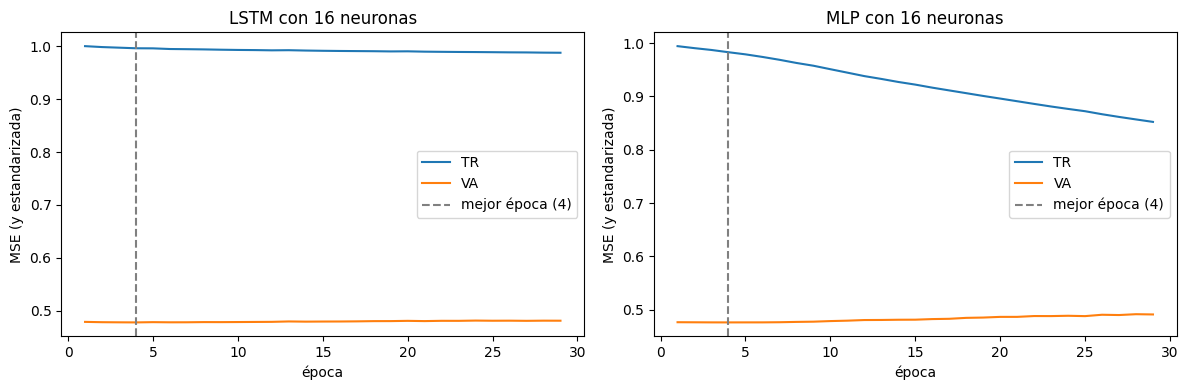

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, r in zip(ejes, mejores.itertuples()):
    c = pd.read_csv(f"outputs/curvas/{r.id}.csv")
    ax.plot(c.epoca, c.perdida_TR, label="TR"); ax.plot(c.epoca, c.perdida_VA, label="VA")
    ax.axvline(r.mejor_epoca, ls="--", c="gray", label=f"mejor época ({r.mejor_epoca})")
    ax.set(title=f"{r.red} con {r.neuronas} neuronas", xlabel="época", ylabel="MSE (y estandarizada)"); ax.legend()
fig.tight_layout(); fig.savefig("figures/fig05_curvas_perdida.png", dpi=120)

## 8. Comparación con el capítulo 7 y selección con VA

In [9]:
ref7 = pd.read_csv(INSUMOS[2])
ref7 = ref7[ref7.conjunto == "VA"][["modelo", "MAE", "RMSE"]].rename(columns={"MAE": "MAE_VA", "RMSE": "RMSE_VA"})
redes = resumen_semillas.assign(modelo=lambda d: d.red + " (" + d.neuronas.astype(str) + " neuronas, media de 3 semillas)")
comparacion = pd.concat([ref7.assign(desv_RMSE_VA=0.0),
                         redes.rename(columns={"MAE_VA_media": "MAE_VA", "RMSE_VA_media": "RMSE_VA", "RMSE_VA_desv": "desv_RMSE_VA"})
                         [["modelo", "MAE_VA", "RMSE_VA", "desv_RMSE_VA"]]], ignore_index=True)
cero = comparacion.RMSE_VA.iloc[0]
comparacion["RMSE_VA_vs_cero_%"] = 100 * (1 - comparacion.RMSE_VA / cero)
elegido = comparacion.loc[comparacion.RMSE_VA.idxmin()]
comparacion.to_csv("outputs/comparacion_va.csv", index=False)
json.dump({"elegido": elegido.modelo, "criterio": "menor RMSE de VA (media de 3 semillas para las redes)",
           "RMSE_VA": float(elegido.RMSE_VA), "mejora_vs_cero_%": float(elegido["RMSE_VA_vs_cero_%"]),
           "modo": "prueba_cpu" if PRUEBA_CPU else "t4", "versiones": VERSIONES},
          open("outputs/seleccion.json", "w"), ensure_ascii=False, indent=1)
print("Elegido con VA:", elegido.modelo, f"(RMSE VA {elegido.RMSE_VA:.5f}; {elegido['RMSE_VA_vs_cero_%']:+.2f} % frente a pronosticar cero)")
comparacion.round(5)

Elegido con VA: Regresión lineal (20 rezagos) (RMSE VA 0.02426; +0.35 % frente a pronosticar cero)


,modelo,MAE_VA,RMSE_VA,desv_RMSE_VA,RMSE_VA_vs_cero_%
0,Cero,0.01722,0.02434,0.00000,0.00000
1,Regresión lineal (20 rezagos),0.01728,0.02426,0.00000,0.34508
2,"LSTM (16 neuronas, media de 3 semillas)",0.01724,0.02430,0.00000,0.19134
3,"MLP (16 neuronas, media de 3 semillas)",0.01723,0.02428,0.00004,0.25564


## 9. Seguimiento: ¿una menor pérdida en TR también mejora VA? Sobreajuste o subajuste
El texto se arma con las cifras de esta corrida (cambian en cada ejecución en T4).

In [10]:
cfg = tabla[tabla.fase == "configuración"]
rho = cfg[["perdida_TR", "RMSE_VA"]].corr(method="spearman").iloc[0, 1]
print(f"Correlación de Spearman entre pérdida de TR y RMSE de VA en las 6 configuraciones: {rho:+.2f}")
print("Si es negativa o cercana a 0, bajar la pérdida de TR no se traduce en mejor VA.")
for r in mejores.itertuples():
    c = pd.read_csv(f"outputs/curvas/{r.id}.csv")
    brecha = c.perdida_VA.iloc[-1] - c.perdida_VA.min()
    tr_baja = c.perdida_TR.iloc[-1] < c.perdida_TR.loc[c.epoca == r.mejor_epoca].item()
    supera_cero = r.RMSE_VA < cero
    if r.mejor_epoca < r.epocas_corridas and tr_baja and brecha > 0:
        diag = (f"sobreajuste: después de la época {r.mejor_epoca} la pérdida de TR siguió bajando y la de VA subió "
                f"{brecha:.4f}; la parada temprana restauró los pesos de la época {r.mejor_epoca}")
    else:
        diag = "sin señal clara de sobreajuste en las épocas corridas"
    if not supera_cero:
        diag += "; además no supera a pronosticar cero en VA, lo que apunta a subajuste o a falta de señal en los rezagos"
    print(f"- {r.red} ({r.neuronas} neuronas): {diag}.")

Correlación de Spearman entre pérdida de TR y RMSE de VA en las 6 configuraciones: -0.14
Si es negativa o cercana a 0, bajar la pérdida de TR no se traduce en mejor VA.
- LSTM (16 neuronas): sobreajuste: después de la época 4 la pérdida de TR siguió bajando y la de VA subió 0.0032; la parada temprana restauró los pesos de la época 4.
- MLP (16 neuronas): sobreajuste: después de la época 4 la pérdida de TR siguió bajando y la de VA subió 0.0149; la parada temprana restauró los pesos de la época 4.


## 10. Resultados fuera del almacenamiento temporal

In [11]:
DESTINO = '/content/respaldo_local_avance2'  # parche: sin Drive, copia local en /content
for d in ['outputs','figures','checkpoints']:
    shutil.copytree(d, f'{DESTINO}/{d}', dirs_exist_ok=True)
print('Copia local:', DESTINO)


Copia local: /content/respaldo_local_avance2


## 11. Comprobación final

In [12]:
chk = {
    "6 configuraciones y 4 repeticiones": (tabla.fase == "configuración").sum() == 6 and (tabla.fase == "repetición").sum() == 4,
    "cada red repetida con 3 semillas": bool((resumen_semillas.corridas == 3).all()),
    "dispositivo registrado en cada experimento": bool(tabla.dispositivo.str.startswith(DISPOSITIVO.type).all()),
    "entrenamiento en T4": ES_T4 and bool(tabla.dispositivo.str.startswith("cuda").all()),
    "mejores pesos restaurados (pérdida VA = mínimo de su curva)": all(
        abs(pd.read_csv(f"outputs/curvas/{r.id}.csv").perdida_VA.min() - r.perdida_VA) < 1e-6 for r in tabla.itertuples()),
    "checkpoints y escaladores guardados": all(os.path.exists(f"checkpoints/{i}.pt") for i in tabla.id) and os.path.exists("checkpoints/escaladores.joblib"),
    "escaladores ajustados solo con TR": escX.n_samples_seen_ == len(P["TR"]),
    "TE sin usar (métricas solo de TR y VA)": not any("TE" in c for c in tabla.columns),
    "curvas guardadas": os.path.getsize("figures/fig05_curvas_perdida.png") > 10_000,
}
for k, v in chk.items():
    print(("OK   " if v else ("PRUEBA CPU " if PRUEBA_CPU and k == "entrenamiento en T4" else "FALLA ")) + k)
json.dump({"modo": "prueba_cpu" if PRUEBA_CPU else "t4", "epocas_max": EPOCAS_MAX, "gpu": GPU,
           "comprobaciones": {k: bool(v) for k, v in chk.items()}, "experimentos": len(tabla), "elegido": elegido.modelo},
          open("outputs/resumen.json", "w"), ensure_ascii=False, indent=1)

OK   6 configuraciones y 4 repeticiones
OK   cada red repetida con 3 semillas
OK   dispositivo registrado en cada experimento
OK   entrenamiento en T4
OK   mejores pesos restaurados (pérdida VA = mínimo de su curva)
OK   checkpoints y escaladores guardados
OK   escaladores ajustados solo con TR
OK   TE sin usar (métricas solo de TR y VA)
OK   curvas guardadas


**Qué sigue (Avance 3, capítulo 9):** tres evaluaciones con ventana expansiva dentro de TR, hasta cinco umbrales de señal
elegidos en VA, y comprobar que TE no intervino en ninguna decisión.